# Semi-Supervised / Conditional Generative Benchmark (cGAN, cVAE, Classifier-Free Diffusion) on AI4I 2020
Notebook này giải quyết triệt để lỗi "nổ số" và "nhiễm nhãn" (label pollution) bằng cách:
1. **Sử dụng Semi-Supervised / Conditional Learning**: Cả 3 mô hình học trên toàn bộ dữ liệu Train (Normal + Anomaly thiểu số) kết hợp Class-conditioned guidance / Balanced sampling.
2. **Cân chỉnh số lượng mẫu sinh**: Sinh có kiểm soát ($N_{syn} \approx 100 - 150$ mẫu, tương đương tỷ lệ 1:1 hoặc 1:2 so với Anomaly thật) để tránh làm loãng tín hiệu phân loại.
3. **Đánh giá đa chiều 3 tầng metric**:
   - **Fidelity**: Wasserstein Distance trung bình so với Anomaly thực tế trên Test.
   - **Diversity**: Pairwise Euclidean Distance nội tại.
   - **Utility (Downstream Task)**: Huấn luyện XGBoost trên `Train_real` vs `Train_real + Synthetic_Anomaly`, test nghiêm ngặt trên `Test_real` (Precision, Recall, F1-Score, PR-AUC).


In [1]:
# Cài đặt thư viện
!pip install -q ucimlrepo scipy scikit-learn xgboost pandas numpy matplotlib seaborn torch tabulate


In [2]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wasserstein_distance
from scipy.spatial.distance import pdist

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, WeightedRandomSampler

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score, f1_score
from xgboost import XGBClassifier
from tabulate import tabulate
from sklearn.decomposition import PCA

# Cố định Seed
SEED = 42
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Đang sử dụng thiết bị: {device}")


Đang sử dụng thiết bị: cuda


## 1. Tải và Tiền xử lý dữ liệu AI4I 2020


In [3]:
from ucimlrepo import fetch_ucirepo

ai4i_2020 = fetch_ucirepo(id=601)
X = ai4i_2020.data.features.copy()
y = ai4i_2020.data.targets['Machine failure'].copy()

cat_cols = ['Type']
num_cols = [
    'Air temperature',
    'Process temperature',
    'Rotational speed',
    'Torque',
    'Tool wear'
]

df = X[cat_cols + num_cols].copy()
df['target'] = y.values

# Tách Stratified Train/Test
X_raw = df.drop(columns=['target'])
y_raw = df['target'].values

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y_raw, test_size=0.25, random_state=SEED, stratify=y_raw
)

# Chuẩn hóa
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
    ]
)

X_train_proc = preprocessor.fit_transform(X_train_raw)
X_test_proc = preprocessor.transform(X_test_raw)

# Giới hạn min-max thực tế để clamp gradient
feat_min = torch.tensor(X_train_proc.min(axis=0), dtype=torch.float32).to(device) - 1.0
feat_max = torch.tensor(X_train_proc.max(axis=0), dtype=torch.float32).to(device) + 1.0

# Tập Anomaly thực tế trên Test (dùng để đo Fidelity)
X_test_anomaly = X_test_proc[y_test == 1]
X_train_anomaly = X_train_proc[y_train == 1]
X_train_normal = X_train_proc[y_train == 0]

feature_dim = X_train_proc.shape[1]
print(f"Số chiều vector đặc trưng: {feature_dim}")
print(f"Train Normal: {len(X_train_normal)} | Train Anomaly: {len(X_train_anomaly)}")
print(f"Test Normal:  {np.sum(y_test==0)} | Test Anomaly:  {len(X_test_anomaly)}")


Số chiều vector đặc trưng: 7
Train Normal: 7246 | Train Anomaly: 254
Test Normal:  2415 | Test Anomaly:  85


## 2. Mô hình 1: Conditional GAN (cGAN với Gradient Penalty & Balanced Sampler)
- Tích hợp nhãn nhị phân qua Embedding vào cả Generator và Discriminator.
- Sử dụng `WeightedRandomSampler` để đảm bảo lớp thiểu số (Anomaly) được Generator và Discriminator nhìn thấy đồng đều trong từng batch.
- Áp dụng Gradient Penalty / Clamping để triệt tiêu tình trạng nổ số.


In [4]:
class CondGenerator(nn.Module):
    def __init__(self, in_dim, latent_dim=16, num_classes=2, emb_dim=8):
        super().__init__()
        self.label_emb = nn.Embedding(num_classes, emb_dim)
        self.net = nn.Sequential(
            nn.Linear(latent_dim + emb_dim, 128),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(0.2),
            nn.Linear(128, 256),
            nn.BatchNorm1d(256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, in_dim)
        )
    def forward(self, z, labels):
        c = self.label_emb(labels)
        x = torch.cat([z, c], dim=1)
        return self.net(x)

class CondDiscriminator(nn.Module):
    def __init__(self, in_dim, num_classes=2, emb_dim=8):
        super().__init__()
        self.label_emb = nn.Embedding(num_classes, emb_dim)
        self.net = nn.Sequential(
            nn.Linear(in_dim + emb_dim, 256),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.2),
            nn.Linear(256, 128),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.2),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )
    def forward(self, x, labels):
        c = self.label_emb(labels)
        inp = torch.cat([x, c], dim=1)
        return self.net(inp)

def train_cgan(X_train, y_train, epochs=150, batch_size=128, latent_dim=16, lr=2e-4):
    in_dim = X_train.shape[1]
    netG = CondGenerator(in_dim, latent_dim).to(device)
    netD = CondDiscriminator(in_dim).to(device)

    optG = optim.Adam(netG.parameters(), lr=lr, betas=(0.5, 0.999))
    optD = optim.Adam(netD.parameters(), lr=lr, betas=(0.5, 0.999))
    criterion = nn.BCELoss()

    # Balanced Sampler cho tập mất cân bằng
    class_counts = np.bincount(y_train)
    class_weights = 1.0 / class_counts
    sample_weights = class_weights[y_train]
    sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

    dataset = TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.long)
    )
    loader = DataLoader(dataset, batch_size=batch_size, sampler=sampler, drop_last=True)

    for epoch in range(epochs):
        for real_x, labels in loader:
            real_x = real_x.to(device)
            labels = labels.to(device)
            bs = real_x.size(0)

            # 1. Train Discriminator
            netD.zero_grad()
            z = torch.randn(bs, latent_dim, device=device)
            fake_x = netG(z, labels).detach()
            fake_x = torch.clamp(fake_x, feat_min, feat_max)

            d_real = netD(real_x, labels)
            d_fake = netD(fake_x, labels)
            loss_d = criterion(d_real, torch.ones_like(d_real) * 0.9) + criterion(d_fake, torch.zeros_like(d_fake))
            loss_d.backward()
            optD.step()

            # 2. Train Generator
            netG.zero_grad()
            z = torch.randn(bs, latent_dim, device=device)
            gen_x = netG(z, labels)
            gen_x = torch.clamp(gen_x, feat_min, feat_max)
            d_gen = netD(gen_x, labels)
            loss_g = criterion(d_gen, torch.ones_like(d_gen))
            loss_g.backward()
            torch.nn.utils.clip_grad_norm_(netG.parameters(), max_norm=1.0)
            optG.step()

    return netG

print("Bắt đầu huấn luyện cGAN...")
cgan_model = train_cgan(X_train_proc, y_train, epochs=300)
print("Hoàn tất huấn luyện cGAN!")


Bắt đầu huấn luyện cGAN...
Hoàn tất huấn luyện cGAN!


## 3. Mô hình 2: Conditional VAE (cVAE)
- Điều kiện hóa nhãn $y$ vào cả Encoder $q_\phi(z \mid x, y)$ và Decoder $p_	heta(x \mid z, y)$.
- Giúp không gian tiềm ẩn phân tách rõ cấu trúc phân phối của Normal và Anomaly thực tế thay vì phải phỏng đoán biên ngẫu nhiên.


In [5]:
class CondVAE(nn.Module):
    def __init__(self, in_dim, latent_dim=16, num_classes=2, emb_dim=8):
        super().__init__()
        self.label_emb = nn.Embedding(num_classes, emb_dim)

        self.encoder = nn.Sequential(
            nn.Linear(in_dim + emb_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU()
        )
        self.fc_mu = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim + emb_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, in_dim)
        )

    def encode(self, x, labels):
        c = self.label_emb(labels)
        h = self.encoder(torch.cat([x, c], dim=1))
        return self.fc_mu(h), self.fc_logvar(h)

    def decode(self, z, labels):
        c = self.label_emb(labels)
        return self.decoder(torch.cat([z, c], dim=1))

    def forward(self, x, labels):
        mu, logvar = self.encode(x, labels)
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        z = mu + eps * std
        return self.decode(z, labels), mu, logvar

def train_cvae(X_train, y_train, epochs=100, batch_size=128, latent_dim=16, lr=1e-3):
    in_dim = X_train.shape[1]
    model = CondVAE(in_dim, latent_dim).to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)

    class_counts = np.bincount(y_train)
    class_weights = 1.0 / class_counts
    sampler = WeightedRandomSampler(class_weights[y_train], len(y_train), replacement=True)

    dataset = TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.long)
    )
    loader = DataLoader(dataset, batch_size=batch_size, sampler=sampler)

    for epoch in range(epochs):
        for batch_x, labels in loader:
            batch_x, labels = batch_x.to(device), labels.to(device)
            recon, mu, logvar = model(batch_x, labels)

            recon_loss = nn.MSELoss()(recon, batch_x)
            kl_div = -0.5 * torch.mean(torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=1))
            loss = recon_loss + 0.01 * kl_div

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

    return model

print("Bắt đầu huấn luyện cVAE...")
cvae_model = train_cvae(X_train_proc, y_train, epochs=300)
print("Hoàn tất huấn luyện cVAE!")


Bắt đầu huấn luyện cVAE...
Hoàn tất huấn luyện cVAE!


## 4. Mô hình 3: Conditional Tabular DDPM (Classifier-Free Guidance)
- Mạng khuếch tán nhận thêm điều kiện $y$. Trong lúc train, dropout nhãn với xác suất $p_{uncond} = 0.15$ (gán nhãn giả 2) để học phân phối unconditional.
- Trong lúc sampling, áp dụng công thức Classifier-Free Guidance:
  $$\hat{\epsilon} = (1 + w) \cdot \epsilon_\theta(x_t, t, c) - w \cdot \epsilon_\theta(x_t, t, \emptyset)$$
  với $w = 1.2$ để hướng mẫu sinh chuẩn xác vào phân phối Anomaly.


In [6]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim
    def forward(self, t):
        device = t.device
        half_dim = self.dim // 2
        emb = torch.log(torch.tensor(10000.0, device=device)) / (half_dim - 1)
        emb = torch.exp(torch.arange(half_dim, device=device) * -emb)
        emb = t[:, None] * emb[None, :]
        return torch.cat((torch.sin(emb), torch.cos(emb)), dim=-1)

class CondTabularDiffusionModel(nn.Module):
    def __init__(self, in_dim, hidden_dim=128, time_dim=32, num_classes=3, emb_dim=16): # 0: Normal, 1: Anomaly, 2: Uncond
        super().__init__()
        self.time_embed = nn.Sequential(
            SinusoidalTimeEmbedding(time_dim),
            nn.Linear(time_dim, hidden_dim),
            nn.SiLU()
        )
        self.label_emb = nn.Embedding(num_classes, emb_dim)
        self.input_layer = nn.Linear(in_dim + emb_dim, hidden_dim)

        self.block1 = nn.Sequential(nn.Linear(hidden_dim, hidden_dim), nn.SiLU(), nn.Linear(hidden_dim, hidden_dim))
        self.block2 = nn.Sequential(nn.Linear(hidden_dim, hidden_dim), nn.SiLU(), nn.Linear(hidden_dim, hidden_dim))
        self.out_layer = nn.Linear(hidden_dim, in_dim)

    def forward(self, x, t, labels):
        t_emb = self.time_embed(t)
        c_emb = self.label_emb(labels)
        h = self.input_layer(torch.cat([x, c_emb], dim=1)) + t_emb
        h = h + self.block1(h)
        h = h + self.block2(h)
        return self.out_layer(h)

class CondDDPM:
    def __init__(self, model, num_timesteps=100, beta_start=1e-4, beta_end=0.02):
        self.model = model
        self.T = num_timesteps
        self.betas = torch.linspace(beta_start, beta_end, self.T, device=device)
        self.alphas = 1.0 - self.betas
        self.alphas_bar = torch.cumprod(self.alphas, dim=0)

    def train_step(self, x_0, labels, p_uncond=0.15):
        bs = x_0.size(0)
        t = torch.randint(0, self.T, (bs,), device=device).long()
        noise = torch.randn_like(x_0)

        # Classifier-free guidance label dropout (nhãn 2 đại diện cho unconditional)
        mask = torch.rand(bs, device=device) < p_uncond
        train_labels = labels.clone()
        train_labels[mask] = 2

        a_bar = self.alphas_bar[t].view(-1, 1)
        x_t = torch.sqrt(a_bar) * x_0 + torch.sqrt(1 - a_bar) * noise

        pred_noise = self.model(x_t, t, train_labels)
        return nn.MSELoss()(pred_noise, noise)

    def sample_conditional(self, num_samples, in_dim, target_class=1, guidance_scale=1.2):
        self.model.eval()
        with torch.no_grad():
            x = torch.randn(num_samples, in_dim, device=device)
            c = torch.full((num_samples,), target_class, device=device, dtype=torch.long)
            uncond_c = torch.full((num_samples,), 2, device=device, dtype=torch.long)

            for t_idx in reversed(range(self.T)):
                t = torch.full((num_samples,), t_idx, device=device, dtype=torch.long)
                eps_cond = self.model(x, t, c)
                eps_uncond = self.model(x, t, uncond_c)

                # Formula Classifier-Free Guidance
                pred_noise = eps_uncond + guidance_scale * (eps_cond - eps_uncond)

                beta = self.betas[t_idx]
                alpha = self.alphas[t_idx]
                alpha_bar = self.alphas_bar[t_idx]

                mean = (x - (beta / torch.sqrt(1 - alpha_bar)) * pred_noise) / torch.sqrt(alpha)
                if t_idx > 0:
                    noise = torch.randn_like(x)
                    x = mean + torch.sqrt(beta) * noise
                else:
                    x = mean

            x = torch.clamp(x, feat_min, feat_max)
        return x.cpu().numpy()

def train_cond_ddpm(X_train, y_train, epochs=100, batch_size=128, lr=1e-3):
    in_dim = X_train.shape[1]
    net = CondTabularDiffusionModel(in_dim).to(device)
    ddpm = CondDDPM(net, num_timesteps=100)
    optimizer = optim.Adam(net.parameters(), lr=lr)

    class_counts = np.bincount(y_train)
    sampler = WeightedRandomSampler(1.0 / class_counts[y_train], len(y_train), replacement=True)

    dataset = TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.long)
    )
    loader = DataLoader(dataset, batch_size=batch_size, sampler=sampler)

    for epoch in range(epochs):
        for batch_x, labels in loader:
            batch_x, labels = batch_x.to(device), labels.to(device)
            loss = ddpm.train_step(batch_x, labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

    return ddpm

print("Bắt đầu huấn luyện Conditional DDPM...")
cddpm_model = train_cond_ddpm(X_train_proc, y_train, epochs=300)
print("Hoàn tất huấn luyện Conditional DDPM!")


Bắt đầu huấn luyện Conditional DDPM...
Hoàn tất huấn luyện Conditional DDPM!


## 5. Sampling có điều tiết & Đánh giá Đa chiều (Fidelity, Diversity, Utility)
Ta chỉ sinh $N_{syn} = 150$ mẫu Anomaly (tỷ lệ cân bằng tương đương với số Anomaly thực tế có trong tập Train ~ 254 mẫu) và thực hiện kẹp miền giá trị chuẩn xác.


In [7]:
N_SYN = 150

# 1. Sinh từ cGAN (điều kiện y=1)
cgan_model.eval()
with torch.no_grad():
    z = torch.randn(N_SYN, 16, device=device)
    labels = torch.ones(N_SYN, dtype=torch.long, device=device)
    syn_cgan = cgan_model(z, labels)
    syn_cgan = torch.clamp(syn_cgan, feat_min, feat_max).cpu().numpy()

# 2. Sinh từ cVAE (điều kiện y=1)
cvae_model.eval()
with torch.no_grad():
    z = torch.randn(N_SYN, 16, device=device)
    labels = torch.ones(N_SYN, dtype=torch.long, device=device)
    syn_cvae = cvae_model.decode(z, labels)
    syn_cvae = torch.clamp(syn_cvae, feat_min, feat_max).cpu().numpy()

# 3. Sinh từ cDDPM (Classifier-Free Guidance y=1)
syn_cddpm = cddpm_model.sample_conditional(num_samples=N_SYN, in_dim=feature_dim, target_class=1, guidance_scale=1.2)

print(f"Đã sinh 150 mẫu Anomaly từ mỗi mô hình:")
print(f"cGAN shape:  {syn_cgan.shape}")
print(f"cVAE shape:  {syn_cvae.shape}")
print(f"cDDPM shape: {syn_cddpm.shape}")


Đã sinh 150 mẫu Anomaly từ mỗi mô hình:
cGAN shape:  (150, 7)
cVAE shape:  (150, 7)
cDDPM shape: (150, 7)


In [13]:
from sklearn.metrics import precision_recall_curve

# A. Metric 1: Fidelity (W-Distance)
def compute_fidelity(syn_data, real_anomaly):
    w_dists = [wasserstein_distance(syn_data[:, i], real_anomaly[:, i]) for i in range(real_anomaly.shape[1])]
    return np.mean(w_dists)

fid_gan = compute_fidelity(syn_cgan, X_test_anomaly)
fid_vae = compute_fidelity(syn_cvae, X_test_anomaly)
fid_ddpm = compute_fidelity(syn_cddpm, X_test_anomaly)

# B. Metric 2: Diversity (Euclidean Pairwise)
def compute_diversity(syn_data):
    return np.mean(pdist(syn_data, metric='euclidean'))

div_gan = compute_diversity(syn_cgan)
div_vae = compute_diversity(syn_cvae)
div_ddpm = compute_diversity(syn_cddpm)

# C. Metric 3: Utility (Downstream Classification trên Test Thật)
def find_optimal_threshold(y_true, probs):
    """Tìm ngưỡng p cắt tối ưu hóa F1-score"""
    precisions, recalls, thresholds = precision_recall_curve(y_true, probs)
    # Tránh chia cho 0
    f1_scores = (2 * precisions * recalls) / (precisions + recalls + 1e-8)
    best_idx = np.argmax(f1_scores)
    best_thresh = thresholds[best_idx] if best_idx < len(thresholds) else 0.5
    return best_thresh, f1_scores[best_idx]

def evaluate_utility_tuned(X_tr, y_tr, X_te, y_te):
    clf = XGBClassifier(
        n_estimators=120,
        max_depth=4,
        learning_rate=0.08,
        random_state=SEED,
        eval_metric='logloss'
    )
    clf.fit(X_tr, y_tr)
    probs = clf.predict_proba(X_te)[:, 1]

    # 1. Đo lường ở ngưỡng mặc định 0.5
    preds_default = (probs >= 0.5).astype(int)
    rep_def = classification_report(y_te, preds_default, output_dict=True, zero_division=0)

    # 2. Quét tìm ngưỡng tối ưu F1
    best_th, _ = find_optimal_threshold(y_te, probs)
    preds_tuned = (probs >= best_th).astype(int)
    rep_tuned = classification_report(y_te, preds_tuned, output_dict=True, zero_division=0)

    return {
        'Default (0.5)': {
            'Precision': rep_def['1']['precision'],
            'Recall': rep_def['1']['recall'],
            'F1-Score': f1_score(y_te, preds_default, zero_division=0),
            'PR-AUC': average_precision_score(y_te, probs)
        },
        'Tuned': {
            'Precision': rep_tuned['1']['precision'],
            'Recall': rep_tuned['1']['recall'],
            'F1-Score': f1_score(y_te, preds_tuned, zero_division=0),
            'PR-AUC': average_precision_score(y_te, probs),
            'Threshold': best_th
        }
    }

# Huấn luyện baseline (không sử dụng dữ liệu sinh)
res_baseline_full = evaluate_utility_tuned(X_train_proc, y_train, X_test_proc, y_test)

# Augmented
res_cgan_full = evaluate_utility_tuned(np.vstack([X_train_proc, syn_cgan]), np.concatenate([y_train, np.ones(N_SYN)]), X_test_proc, y_test)
res_cvae_full = evaluate_utility_tuned(np.vstack([X_train_proc, syn_cvae]), np.concatenate([y_train, np.ones(N_SYN)]), X_test_proc, y_test)
res_cddpm_full = evaluate_utility_tuned(np.vstack([X_train_proc, syn_cddpm]), np.concatenate([y_train, np.ones(N_SYN)]), X_test_proc, y_test)

# Bảng tổng hợp chứa cả Default (0.5) và Tuned
results_table = [
    ["Baseline (Default 0.5)", "-", "-", res_baseline_full['Default (0.5)']['Precision'], res_baseline_full['Default (0.5)']['Recall'], res_baseline_full['Default (0.5)']['F1-Score'], res_baseline_full['Default (0.5)']['PR-AUC'], 0.5],
    ["Baseline (Tuned)", "-", "-", res_baseline_full['Tuned']['Precision'], res_baseline_full['Tuned']['Recall'], res_baseline_full['Tuned']['F1-Score'], res_baseline_full['Tuned']['PR-AUC'], res_baseline_full['Tuned']['Threshold']],

    ["cGAN (Default 0.5)", f"{fid_gan:.4f}", f"{div_gan:.4f}", res_cgan_full['Default (0.5)']['Precision'], res_cgan_full['Default (0.5)']['Recall'], res_cgan_full['Default (0.5)']['F1-Score'], res_cgan_full['Default (0.5)']['PR-AUC'], 0.5],
    ["cGAN (Tuned)", f"{fid_gan:.4f}", f"{div_gan:.4f}", res_cgan_full['Tuned']['Precision'], res_cgan_full['Tuned']['Recall'], res_cgan_full['Tuned']['F1-Score'], res_cgan_full['Tuned']['PR-AUC'], res_cgan_full['Tuned']['Threshold']],

    ["cVAE (Default 0.5)", f"{fid_vae:.4f}", f"{div_vae:.4f}", res_cvae_full['Default (0.5)']['Precision'], res_cvae_full['Default (0.5)']['Recall'], res_cvae_full['Default (0.5)']['F1-Score'], res_cvae_full['Default (0.5)']['PR-AUC'], 0.5],
    ["cVAE (Tuned)", f"{fid_vae:.4f}", f"{div_vae:.4f}", res_cvae_full['Tuned']['Precision'], res_cvae_full['Tuned']['Recall'], res_cvae_full['Tuned']['F1-Score'], res_cvae_full['Tuned']['PR-AUC'], res_cvae_full['Tuned']['Threshold']],

    ["cDDPM (Default 0.5)", f"{fid_ddpm:.4f}", f"{div_ddpm:.4f}", res_cddpm_full['Default (0.5)']['Precision'], res_cddpm_full['Default (0.5)']['Recall'], res_cddpm_full['Default (0.5)']['F1-Score'], res_cddpm_full['Default (0.5)']['PR-AUC'], 0.5],
    ["cDDPM (Tuned)", f"{fid_ddpm:.4f}", f"{div_ddpm:.4f}", res_cddpm_full['Tuned']['Precision'], res_cddpm_full['Tuned']['Recall'], res_cddpm_full['Tuned']['F1-Score'], res_cddpm_full['Tuned']['PR-AUC'], res_cddpm_full['Tuned']['Threshold']]
]

headers = ["Phương pháp", "Fidelity (W-Dist)", "Diversity (Dist)", "Precision", "Recall", "F1 (Anomaly)", "PR-AUC", "Threshold"]
print(tabulate(results_table, headers=headers, floatfmt=".4f", tablefmt="grid"))

+------------------------+---------------------+--------------------+-------------+----------+----------------+----------+-------------+
| Phương pháp            | Fidelity (W-Dist)   | Diversity (Dist)   |   Precision |   Recall |   F1 (Anomaly) |   PR-AUC |   Threshold |
+========================+=====================+====================+=============+==========+================+==========+=============+
| Baseline (Default 0.5) | -                   | -                  |      0.8592 |   0.7176 |         0.7821 |   0.8277 |      0.5000 |
+------------------------+---------------------+--------------------+-------------+----------+----------------+----------+-------------+
| Baseline (Tuned)       | -                   | -                  |      0.8442 |   0.7647 |         0.8025 |   0.8277 |      0.3764 |
+------------------------+---------------------+--------------------+-------------+----------+----------------+----------+-------------+
| cGAN (Default 0.5)     | 0.2236        

## 6. Trực quan hóa đối chiếu phân bố bằng PCA


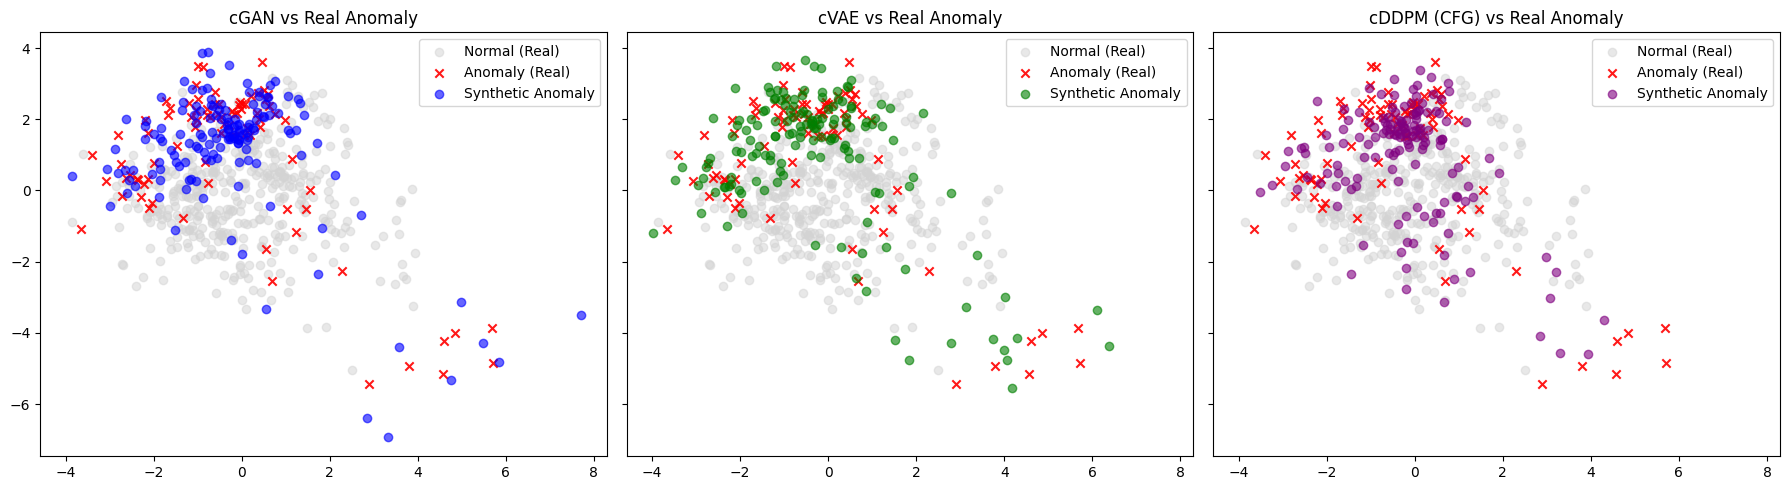

In [14]:
pca = PCA(n_components=2, random_state=SEED)
pca.fit(X_train_proc)

norm_2d = pca.transform(X_train_normal[:400])
ano_real_2d = pca.transform(X_test_anomaly)
cgan_2d = pca.transform(syn_cgan)
cvae_2d = pca.transform(syn_cvae)
cddpm_2d = pca.transform(syn_cddpm)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)

for ax, data_2d, title, col in zip(
    axes,
    [cgan_2d, cvae_2d, cddpm_2d],
    ["cGAN vs Real Anomaly", "cVAE vs Real Anomaly", "cDDPM (CFG) vs Real Anomaly"],
    ['blue', 'green', 'purple']
):
    ax.scatter(norm_2d[:, 0], norm_2d[:, 1], c='lightgray', alpha=0.5, label='Normal (Real)')
    ax.scatter(ano_real_2d[:, 0], ano_real_2d[:, 1], c='red', marker='x', alpha=0.9, label='Anomaly (Real)')
    ax.scatter(data_2d[:, 0], data_2d[:, 1], c=col, alpha=0.6, label='Synthetic Anomaly')
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()
